<a href="https://colab.research.google.com/github/chan-hee03/ML-programing/blob/main/WISDM_kfold.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **WISDM v1.1 활동 분류**
UCI-HAR 분류 방식을 WISDM에 적용하기 위한 노트북 (1단계: 데이터 로딩 및 확인)

In [13]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf


# ============================================================
# 1. Seed
# ============================================================

SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)


# ============================================================
# 2. Path / 상수
# ============================================================

# WISDM_ar_v1.1_raw.txt 를 Drive에 올려둔 위치로 수정
DATA_PATH = "/content/drive/MyDrive/MLP/WISDM_ar_v1.1_raw.txt"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(f"데이터 파일을 찾을 수 없음: {DATA_PATH}")

print("Dataset found")
print(DATA_PATH)

COLUMNS = ["user", "activity", "timestamp", "x", "y", "z"]

# 클래스 순서 (라벨 0~5)
class_names = ["Walking", "Jogging", "Upstairs", "Downstairs", "Sitting", "Standing"]
label_map = {name: i for i, name in enumerate(class_names)}

SAMPLING_RATE = 20   # Hz (논문 기준, 아래에서 실제 간격 확인)

Dataset found
/content/drive/MyDrive/MLP/WISDM_ar_v1.1_raw.txt


In [15]:
# ============================================================
# 3. Load raw data
#   파일 특성:
#   - 레코드 형식: user,activity,timestamp,x,y,z;
#   - 일부 레코드는 끝에 ',;' 처럼 쉼표가 하나 더 붙어 있음
#   - 한 줄에 레코드 2개가 붙어 있는 경우가 있음 (줄바꿈 누락)
#   - 값이 빠진 불완전 레코드가 있음
#   -> 세미콜론 기준으로 레코드를 나눠 한 개씩 파싱하고, 형식이 깨진 것은 따로 모음
# ============================================================

def load_wisdm_raw(path):

    records = []
    bad_records = []

    with open(path, "r", errors="ignore") as f:

        for line_no, line in enumerate(f, start=1):

            for rec in line.strip().split(";"):

                rec = rec.strip().rstrip(",")

                if not rec:
                    continue

                parts = rec.split(",")

                if len(parts) != 6:
                    bad_records.append((line_no, rec))
                    continue

                try:
                    records.append((
                        int(parts[0]),
                        parts[1].strip(),
                        int(parts[2]),
                        float(parts[3]),
                        float(parts[4]),
                        float(parts[5])
                    ))
                except ValueError:
                    bad_records.append((line_no, rec))

    df = pd.DataFrame(records, columns=COLUMNS)

    return df, bad_records


df_raw, bad_records = load_wisdm_raw(DATA_PATH)

print("파싱된 레코드 수:", len(df_raw))
print("형식이 깨진 레코드 수:", len(bad_records))
for line_no, rec in bad_records:
    print(f"  line {line_no}: {rec}")

파싱된 레코드 수: 1098208
형식이 깨진 레코드 수: 1
  line 343420: 11,Walking,1867172313000,4.4,4.4


In [16]:
# ============================================================
# 4. 기본 정리 (데이터셋 다듬기)
#   4-1. timestamp == 0 레코드 제거 (센서 오류)
#   4-2. 연속으로 반복된 레코드 제거 (첫 번째만 유지)
#   4-3. 통째로 중복 기록된 구간 제거
#   4-4. 활동 이름 -> 정수 라벨
#   - 원본 df_raw는 그대로 유지 (셀 반복 실행해도 안전)
# ============================================================

n_start = len(df_raw)

# ------------------------------------------------------------
# 4-1. timestamp == 0 레코드 제거
#   (대부분 x, y, z도 전부 0인 센서 오류 데이터)
# ------------------------------------------------------------
zero_ts = df_raw["timestamp"] == 0
zero_ts_all_zero = zero_ts & (df_raw[["x", "y", "z"]] == 0).all(axis=1)

print("=" * 60)
print("4-1. timestamp == 0 레코드 제거")
print("=" * 60)
print("제거 대상:", int(zero_ts.sum()))
print("  그중 x, y, z도 모두 0:", int(zero_ts_all_zero.sum()))
print("  활동별:", df_raw.loc[zero_ts, "activity"].value_counts().to_dict())

df = df_raw[~zero_ts].reset_index(drop=True)
n_after_zero = len(df)

# ------------------------------------------------------------
# 4-2. 연속으로 반복된 레코드 제거
#   바로 앞 행과 모든 열(user, activity, timestamp, x, y, z)이 같으면
#   값이 갱신되지 않고 다시 기록된 것으로 보고 제거
# ------------------------------------------------------------
same_as_prev = df[COLUMNS].eq(df[COLUMNS].shift()).all(axis=1)

print("\n" + "=" * 60)
print("4-2. 연속으로 반복된 레코드 제거")
print("=" * 60)
print("제거 대상:", int(same_as_prev.sum()))
print("  활동별:", df.loc[same_as_prev, "activity"].value_counts().to_dict())

df = df[~same_as_prev].reset_index(drop=True)
n_after_adj = len(df)

# ------------------------------------------------------------
# 4-3. 통째로 중복 기록된 구간 제거
#   - 구간(segment): user, activity가 바뀌지 않고 이어지는 행 묶음
#   - 구간 안의 레코드 대부분이 파일 앞쪽에 이미 있는 레코드와 같으면
#     같은 데이터가 두 번 들어간 것으로 보고 구간 전체를 제거
#     (중복 레코드만 빼면 남은 소수의 레코드가 조각난 채 남기 때문)
# ------------------------------------------------------------
DUP_SEGMENT_RATIO = 0.5   # 구간 내 중복 비율이 이 값을 넘으면 구간 전체 제거

segment_tmp = (
    (df["user"] != df["user"].shift()) |
    (df["activity"] != df["activity"].shift())
).cumsum()

is_dup = df.duplicated(subset=COLUMNS, keep="first")
seg_dup_ratio = is_dup.groupby(segment_tmp).mean()
dup_segments = seg_dup_ratio[seg_dup_ratio > DUP_SEGMENT_RATIO].index

print("\n" + "=" * 60)
print("4-3. 통째로 중복 기록된 구간 제거")
print("=" * 60)
print("중복 레코드 (파일 앞쪽에 같은 레코드가 있음):", int(is_dup.sum()))
print(f"중복 비율 {DUP_SEGMENT_RATIO:.0%} 초과 구간 수:", len(dup_segments))

drop_mask = segment_tmp.isin(dup_segments)

for seg in dup_segments:
    rows = df[segment_tmp == seg]
    print(f"  user {rows['user'].iloc[0]:2d}, {rows['activity'].iloc[0]:10s}: "
          f"{len(rows):6d}개 (중복 비율 {seg_dup_ratio[seg]:.1%})")

df = df[~drop_mask].reset_index(drop=True)
n_after_seg = len(df)

# 남은 중복 확인 (0이어야 정상)
remaining_dup = int(df.duplicated(subset=COLUMNS).sum())
print("\n구간 제거 후 남은 중복 레코드:", remaining_dup)

# ------------------------------------------------------------
# 4-4. 활동 이름 -> 정수 라벨
# ------------------------------------------------------------
# 알 수 없는 활동 이름이 있는지 확인
unknown = set(df["activity"].unique()) - set(class_names)
assert not unknown, f"알 수 없는 활동 이름: {unknown}"

df["label"] = df["activity"].map(label_map).astype(int)

# ------------------------------------------------------------
# 요약
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("요약 (레코드 수)")
print("=" * 60)
print(f"원본                 : {n_start:9d}")
print(f"4-1 timestamp 0 제거 : {n_after_zero:9d}  (-{n_start - n_after_zero})")
print(f"4-2 연속 반복 제거   : {n_after_adj:9d}  (-{n_after_zero - n_after_adj})")
print(f"4-3 중복 구간 제거   : {n_after_seg:9d}  (-{n_after_adj - n_after_seg})")
print(f"총 제거              : {n_start - n_after_seg:9d}  "
      f"({(n_start - n_after_seg) / n_start:.2%})")

print("\n활동별 레코드 수 (정리 전 -> 후)")
before = df_raw["activity"].value_counts()
after = df["activity"].value_counts()
for name in class_names:
    print(f"  {name:11s}: {before.get(name, 0):7d} -> {after.get(name, 0):7d}")

print()
print(df.head())
print()
print(df.dtypes)

# ------------------------------------------------------------
# 4-5. 연속 구간(segment) 생성
#   아래 중 하나라도 해당하면 새 구간 시작
#   - user가 바뀜
#   - activity가 바뀜
#   - 앞 레코드와의 시간 간격이 GAP_SEC초 초과 (기록이 끊긴 지점)
#   - 시간이 거꾸로 감 (다른 기록이 이어 붙은 지점, 안전장치)
#   -> 한 segment 안의 데이터는 "같은 사람, 같은 활동, 끊김 없는 기록"
#   -> 이후 시각화 / 윈도우 분할은 segment 경계를 넘지 않게 처리
# ------------------------------------------------------------
GAP_SEC = 1.0

dt_sec = df["timestamp"].diff() / 1e9                       # ns -> 초

user_change = df["user"] != df["user"].shift()
act_change = df["activity"] != df["activity"].shift()
same_rec = ~(user_change | act_change)                      # user, activity 그대로인 지점
time_gap = same_rec & (dt_sec > GAP_SEC)
time_back = same_rec & (dt_sec < 0)

new_segment = user_change | act_change | time_gap | time_back
df["segment"] = new_segment.cumsum() - 1                    # 0부터 시작

seg_len = df.groupby("segment").size()

print("\n" + "=" * 60)
print("4-5. 연속 구간(segment) 생성")
print("=" * 60)

print("\nsegment 길이")
print(f"  레코드 수 : 최소 {seg_len.min()}, 중앙값 {int(seg_len.median())}, 최대 {seg_len.max()}")
print(f"  시간(초)  : 최소 {seg_len.min() / SAMPLING_RATE:.1f}, "
      f"중앙값 {seg_len.median() / SAMPLING_RATE:.1f}, "
      f"최대 {seg_len.max() / SAMPLING_RATE:.1f}  (20Hz 기준 환산)")

4-1. timestamp == 0 레코드 제거
제거 대상: 12845
  그중 x, y, z도 모두 0: 12841
  활동별: {'Jogging': 11848, 'Walking': 492, 'Upstairs': 271, 'Downstairs': 233, 'Standing': 1}

4-2. 연속으로 반복된 레코드 제거
제거 대상: 41867
  활동별: {'Jogging': 20904, 'Walking': 10702, 'Upstairs': 3676, 'Downstairs': 2811, 'Sitting': 2624, 'Standing': 1150}

4-3. 통째로 중복 기록된 구간 제거
중복 레코드 (파일 앞쪽에 같은 레코드가 있음): 12151
중복 비율 50% 초과 구간 수: 2
  user 19, Jogging   :   6345개 (중복 비율 100.0%)
  user 19, Walking   :   5806개 (중복 비율 100.0%)

구간 제거 후 남은 중복 레코드: 0

요약 (레코드 수)
원본                 :   1098208
4-1 timestamp 0 제거 :   1085363  (-12845)
4-2 연속 반복 제거   :   1043496  (-41867)
4-3 중복 구간 제거   :   1031345  (-12151)
총 제거              :     66863  (6.09%)

활동별 레코드 수 (정리 전 -> 후)
  Walking    :  424399 ->  407399
  Jogging    :  342179 ->  303082
  Upstairs   :  122869 ->  118922
  Downstairs :  100427 ->   97383
  Sitting    :   59939 ->   57315
  Standing   :   48395 ->   47244

   user activity       timestamp         x          y         z  label
0

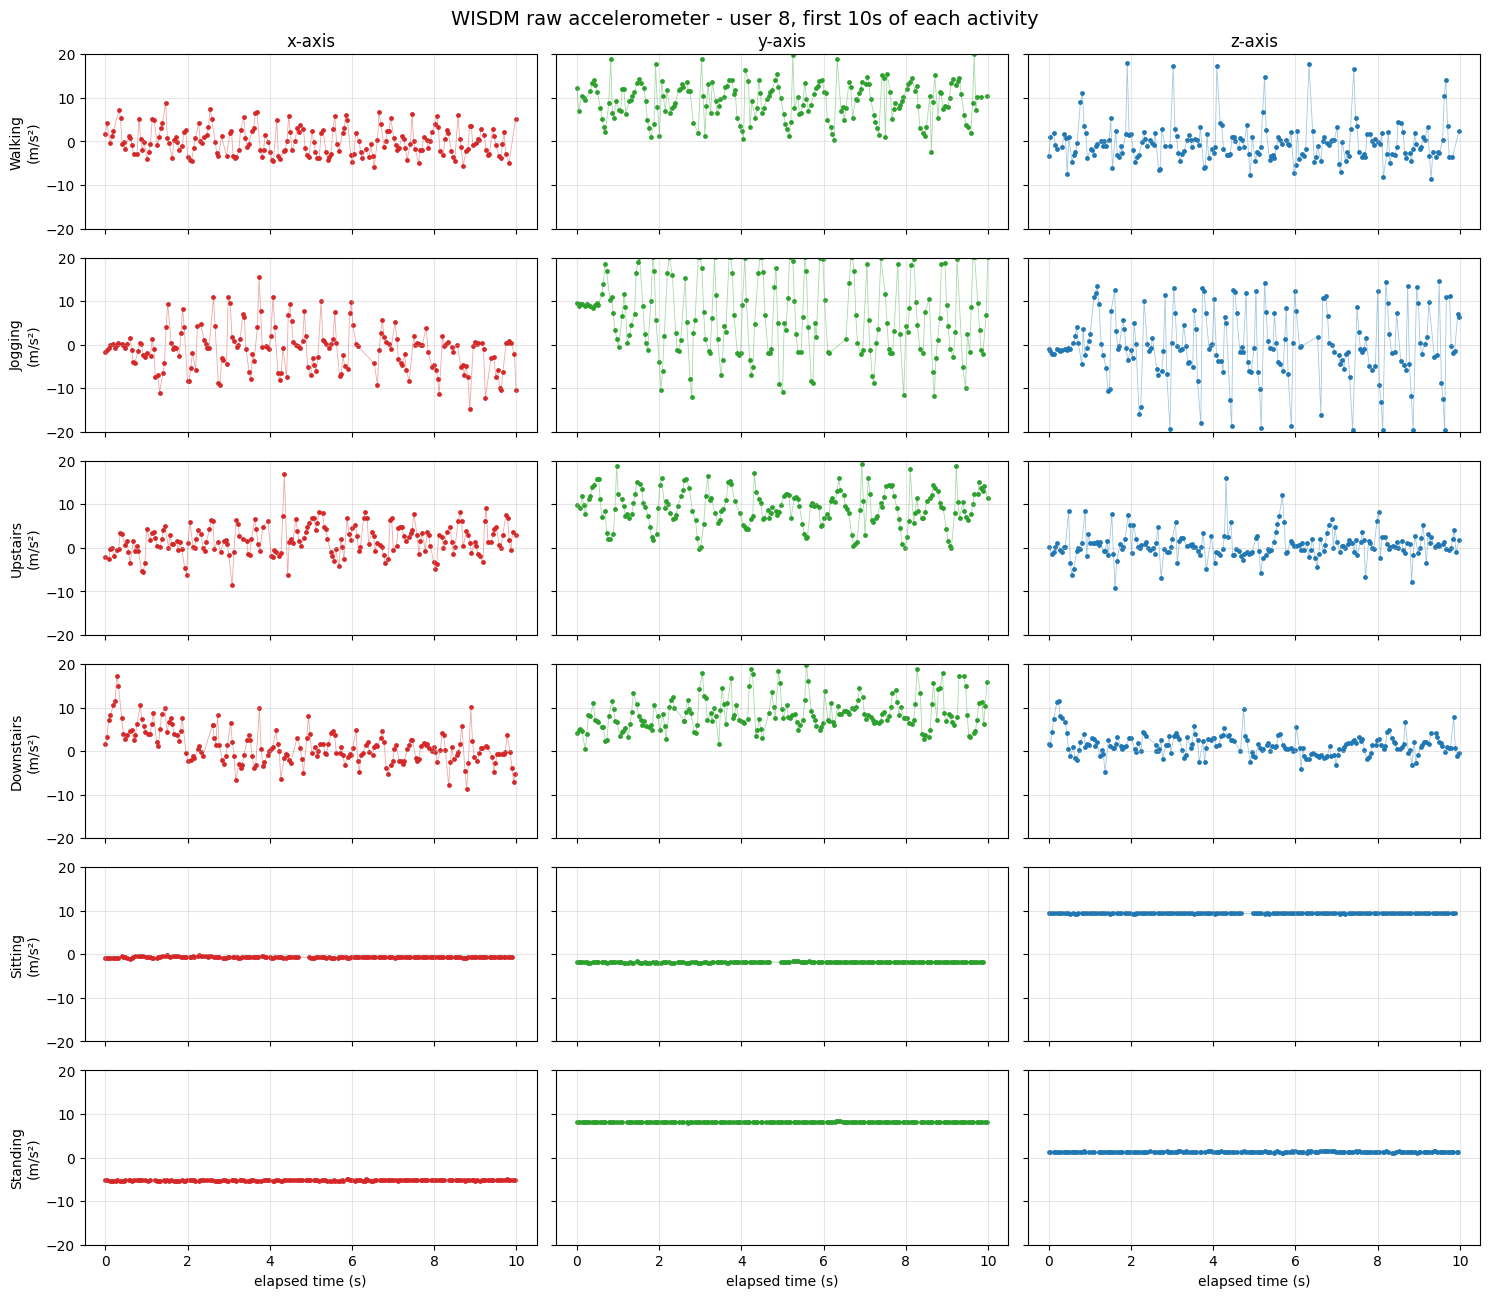

활동별 가속도 통계 (전체 피험자, 단위: m/s²)
             count     x           y           z      
                    mean   std  mean   std  mean   std
activity                                              
Walking     407399  1.54  5.73  8.75  4.95 -0.08  4.01
Jogging     303082 -0.21  9.16  5.71  9.33 -0.14  5.97
Upstairs    118922  0.36  5.51  8.14  4.87  0.31  3.57
Downstairs   97383  0.44  4.95  8.65  4.86  0.68  3.71
Sitting      57315  1.83  4.76  1.87  3.27  6.56  3.74
Standing     47244 -1.18  3.24  8.98  1.27  0.58  1.38


In [17]:
import matplotlib.pyplot as plt

# ============================================================
# 5. 데이터셋 시각화 + 통계
#   - 피험자 1명을 골라 활동별로 첫 번째 segment의 앞부분 PLOT_SECONDS초만 그림
#   - segment는 4-5에서 생성 (같은 사람, 같은 활동, 끊김 없는 기록)
#   - x축: 구간 시작부터 경과 시간(초)  (timestamp 단위: ns)
#   - 점 + 옅은 선으로 표시
# ============================================================

PLOT_USER = 8        # 6개 활동이 모두 있는 피험자로 선택
PLOT_SECONDS = 10    # 활동별로 그릴 길이 (초)

# ------------------------------------------------------------
# 1. 선택한 피험자 데이터 추출
# ------------------------------------------------------------
df_user = df[df["user"] == PLOT_USER]

missing_acts = set(class_names) - set(df_user["activity"].unique())
assert not missing_acts, f"user {PLOT_USER}에 없는 활동: {missing_acts}"

# ------------------------------------------------------------
# 2. 그래프: 6행(활동) x 3열(x, y, z)
#   - 활동마다 첫 번째 segment의 앞부분 PLOT_SECONDS초
#   - 모든 subplot의 y축 범위를 같게 해서 활동 간 비교가 쉽게 함
# ------------------------------------------------------------
axes_names = ["x", "y", "z"]
colors = ["tab:red", "tab:green", "tab:blue"]

fig, axes = plt.subplots(
    len(class_names), 3,
    figsize=(15, 2.2 * len(class_names)),
    sharex=True, sharey=True
)

for row, act in enumerate(class_names):

    first_seg = df_user.loc[df_user["activity"] == act, "segment"].iloc[0]
    seg = df_user[df_user["segment"] == first_seg]

    elapsed = (seg["timestamp"] - seg["timestamp"].iloc[0]) / 1e9   # ns -> 초
    in_range = elapsed <= PLOT_SECONDS

    for col, (axis, color) in enumerate(zip(axes_names, colors)):
        ax = axes[row, col]
        ax.plot(elapsed[in_range], seg.loc[in_range, axis],
                color=color, linewidth=0.6, alpha=0.4)
        ax.scatter(elapsed[in_range], seg.loc[in_range, axis],
                   color=color, s=6)
        ax.grid(alpha=0.3)

        if row == 0:
            ax.set_title(f"{axis}-axis", fontsize=12)
        if col == 0:
            ax.set_ylabel(f"{act}\n(m/s²)", fontsize=10)
        if row == len(class_names) - 1:
            ax.set_xlabel("elapsed time (s)")

axes[0, 0].set_ylim(-20, 20)
fig.suptitle(f"WISDM raw accelerometer - user {PLOT_USER}, first {PLOT_SECONDS}s of each activity",
             fontsize=14)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. 통계: 활동별 x, y, z 평균 / 표준편차 (전체 피험자 기준)
#   - 평균: 중력 방향 차이 (예: Sitting vs Standing)
#   - 표준편차: 흔들림 크기 차이 (예: Walking vs Jogging)
# ------------------------------------------------------------
stats = df.groupby("activity")[axes_names].agg(["mean", "std"]).loc[class_names]
stats.insert(0, "count", df["activity"].value_counts().loc[class_names])

print("=" * 60)
print("활동별 가속도 통계 (전체 피험자, 단위: m/s²)")
print("=" * 60)
print(stats.round(2))

In [18]:
# ============================================================
# 6. 윈도우 분할 (슬라이딩 윈도우)
#   - segment(같은 사람, 같은 활동, 끊김 없는 기록) 안에서만 자름
#   - 길이 WINDOW_SIZE, 간격 STEP (50% 겹침)
#   - segment 끝에 WINDOW_SIZE보다 짧게 남는 부분, 짧은 segment는 버림
#   - 결과:
#       X_all       : (윈도우 수, WINDOW_SIZE, 3)  x, y, z 신호
#       y_all       : (윈도우 수,)  라벨 0~5
#       subject_all : (윈도우 수,)  피험자 ID (train/test 분할, GroupKFold용)
#       segment_all : (윈도우 수,)  윈도우가 나온 segment 번호 (추적용)
# ============================================================

WINDOW_SIZE = 80     # 80샘플 = 4초 (20Hz)
STEP = 40            # 50% 겹침

SIGNAL_COLS = ["x", "y", "z"]

X_list, y_list, subject_list, segment_list = [], [], [], []

n_short_segments = 0     # WINDOW_SIZE보다 짧아서 통째로 버린 segment 수
n_short_records = 0      # 그 segment들의 레코드 수
n_tail_records = 0       # segment 끝에서 잘려 나간 자투리 레코드 수

for seg_id, seg in df.groupby("segment", sort=True):

    n = len(seg)

    if n < WINDOW_SIZE:
        n_short_segments += 1
        n_short_records += n
        continue

    # segment 안은 user, label이 하나뿐이어야 함 (4-5 생성 규칙 확인)
    assert seg["user"].nunique() == 1 and seg["label"].nunique() == 1

    values = seg[SIGNAL_COLS].to_numpy(dtype=np.float32)          # (n, 3)

    # (n - WINDOW_SIZE + 1, 1, WINDOW_SIZE, 3) -> STEP 간격으로 선택 -> (윈도우 수, WINDOW_SIZE, 3)
    windows = np.lib.stride_tricks.sliding_window_view(
        values, (WINDOW_SIZE, len(SIGNAL_COLS))
    )[::STEP, 0]

    n_win = len(windows)
    n_tail_records += n - ((n_win - 1) * STEP + WINDOW_SIZE)

    X_list.append(windows)
    y_list.append(np.full(n_win, seg["label"].iloc[0]))
    subject_list.append(np.full(n_win, seg["user"].iloc[0]))
    segment_list.append(np.full(n_win, seg_id))

X_all = np.concatenate(X_list).astype(np.float32)   # view -> 독립 배열로 복사
y_all = np.concatenate(y_list).astype(int)
subject_all = np.concatenate(subject_list).astype(int)
segment_all = np.concatenate(segment_list).astype(int)

# ------------------------------------------------------------
# 확인 1: 결과 모양 / 버려진 데이터
# ------------------------------------------------------------
print("=" * 60)
print(f"윈도우 분할 결과 (WINDOW_SIZE={WINDOW_SIZE}, STEP={STEP})")
print("=" * 60)
print("X_all      :", X_all.shape)
print("y_all      :", y_all.shape)
print("subject_all:", subject_all.shape)

n_total = len(df)
print(f"\n전체 레코드                : {n_total}")
print(f"짧아서 버린 segment        : {n_short_segments}개 ({n_short_records} 레코드)")
print(f"segment 끝 자투리로 버린 수: {n_tail_records} 레코드")
print(f"윈도우에 한 번 이상 포함   : {n_total - n_short_records - n_tail_records} 레코드 "
      f"({(n_total - n_short_records - n_tail_records) / n_total:.2%})")

# ------------------------------------------------------------
# 확인 2: 클래스별 / 피험자별 윈도우 수
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("클래스별 윈도우 수")
print("=" * 60)
win_counts = np.bincount(y_all, minlength=len(class_names))
for i, name in enumerate(class_names):
    print(f"{i} {name:11s}: {win_counts[i]:6d}  ({win_counts[i] / len(y_all) * 100:5.1f}%)")

print("\n" + "=" * 60)
print("피험자별 윈도우 수 (0 = 해당 활동 없음)")
print("=" * 60)
win_table = pd.crosstab(
    pd.Series(subject_all, name="user"),
    pd.Series([class_names[i] for i in y_all], name="activity")
).reindex(columns=class_names, fill_value=0)
win_table["total"] = win_table.sum(axis=1)
print(win_table)

# ------------------------------------------------------------
# 확인 3: 윈도우 하나를 원본 df와 직접 비교 (분할이 정확한지)
# ------------------------------------------------------------
check_idx = len(X_all) // 2
check_seg = segment_all[check_idx]
k = check_idx - np.where(segment_all == check_seg)[0][0]    # 해당 segment 안에서 몇 번째 윈도우인지
expected = df.loc[df["segment"] == check_seg, SIGNAL_COLS].to_numpy(dtype=np.float32)[k * STEP : k * STEP + WINDOW_SIZE]

print("\n" + "=" * 60)
print("윈도우 검증")
print("=" * 60)
print(f"윈도우 {check_idx}: segment {check_seg}의 {k}번째 윈도우, "
      f"user {subject_all[check_idx]}, {class_names[y_all[check_idx]]}")
print("원본 df 구간과 일치:", np.array_equal(X_all[check_idx], expected))

윈도우 분할 결과 (WINDOW_SIZE=80, STEP=40)
X_all      : (25148, 80, 3)
y_all      : (25148,)
subject_all: (25148,)

전체 레코드                : 1031345
짧아서 버린 segment        : 7개 (93 레코드)
segment 끝 자투리로 버린 수: 8132 레코드
윈도우에 한 번 이상 포함   : 1023120 레코드 (99.20%)

클래스별 윈도우 수
0 Walking    :  10091  ( 40.1%)
1 Jogging    :   7473  ( 29.7%)
2 Upstairs   :   2783  ( 11.1%)
3 Downstairs :   2253  (  9.0%)
4 Sitting    :   1400  (  5.6%)
5 Standing   :   1148  (  4.6%)

피험자별 윈도우 수 (0 = 해당 활동 없음)
activity  Walking  Jogging  Upstairs  Downstairs  Sitting  Standing  total
user                                                                      
1             315      269        71          67        0         0    722
2             289      289         0           0        0         0    578
3             317      269        78          74       37        67    842
4             149       21        31          39       29         0    269
5             298      156        70          74       38        35    6

In [19]:
# ============================================================
# 7. Train / Test 분할 (피험자 단위)
#   - WISDM은 공식 분할이 없음 -> UCI 실습과 같은 방식 사용
#     피험자 ID 순으로 정렬 후 뒤쪽 TEST_RATIO 만큼을 test로
#   - 단, 자르는 위치를 "목표 비율에 가장 가까운 피험자 경계"로 맞춤
#     -> train / test에 같은 피험자가 섞이지 않음 (섞이는 피험자 0명)
#     (피험자 중간에서 자르면 segment 중간이 잘려
#      50% 겹친 윈도우가 train/test 양쪽에 들어가는 누수 발생)
# ============================================================

TEST_RATIO = 0.3     # 목표 test 비율 (윈도우 수 기준)


def split_by_subject_tail(subjects, test_ratio):
    """
    피험자 ID 순으로 정렬해 뒤쪽 test_ratio 만큼을 test로 나눔
    자르는 위치는 목표 비율에 가장 가까운 피험자 경계

    반환: train_mask, test_mask (윈도우 단위 bool 배열), test 피험자 목록
    """
    uniq = np.unique(subjects)                                  # 오름차순 정렬된 피험자 ID
    counts = np.array([(subjects == u).sum() for u in uniq])    # 피험자별 윈도우 수

    # 뒤에서부터 피험자를 하나씩 test에 넣었을 때의 누적 비율
    tail_ratio = np.cumsum(counts[::-1]) / len(subjects)        # 1명, 2명, ... 넣었을 때
    n_test_subjects = int(np.argmin(np.abs(tail_ratio - test_ratio))) + 1

    test_subjects = uniq[-n_test_subjects:]
    test_mask = np.isin(subjects, test_subjects)

    return ~test_mask, test_mask, test_subjects


train_mask, test_mask, test_subjects = split_by_subject_tail(subject_all, TEST_RATIO)

X_train, y_train = X_all[train_mask], y_all[train_mask]
X_test,  y_test  = X_all[test_mask],  y_all[test_mask]

subject_train, subject_test = subject_all[train_mask], subject_all[test_mask]   # GroupKFold용
segment_train, segment_test = segment_all[train_mask], segment_all[test_mask]   # 추적용

# ------------------------------------------------------------
# 확인 1: 피험자 / 모양
# ------------------------------------------------------------
train_subjects = np.unique(subject_train)

print("=" * 60)
print(f"Train / Test 분할 (목표 test 비율 {TEST_RATIO:.0%})")
print("=" * 60)
print(f"Train 피험자 ({len(train_subjects)}명): {train_subjects.tolist()}")
print(f"Test  피험자 ({len(test_subjects)}명): {test_subjects.tolist()}")
print(f"\n실제 test 비율: {test_mask.mean():.2%}")
print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_test :", X_test.shape,  " y_test :", y_test.shape)

# ------------------------------------------------------------
# 확인 2: 누수 점검 (둘 다 0이어야 정상)
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("누수 점검")
print("=" * 60)
print("train/test 겹치는 피험자:", len(set(subject_train) & set(subject_test)))
print("train/test 겹치는 segment:", len(set(segment_train) & set(segment_test)))

# ------------------------------------------------------------
# 확인 3: 클래스별 윈도우 수 / test 비율
# ------------------------------------------------------------
train_counts = np.bincount(y_train, minlength=len(class_names))
test_counts = np.bincount(y_test, minlength=len(class_names))

print("\n" + "=" * 60)
print("클래스별 윈도우 수")
print("=" * 60)
print(f"{'':13s}{'train':>8s}{'test':>8s}{'test 비율':>11s}")
for i, name in enumerate(class_names):
    total = train_counts[i] + test_counts[i]
    print(f"{i} {name:11s}{train_counts[i]:8d}{test_counts[i]:8d}"
          f"{test_counts[i] / total:10.1%}")
print(f"{'  합계':13s}{train_counts.sum():8d}{test_counts.sum():8d}"
      f"{test_counts.sum() / len(y_all):10.1%}")

Train / Test 분할 (목표 test 비율 30%)
Train 피험자 (26명): [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26]
Test  피험자 (10명): [27, 28, 29, 30, 31, 32, 33, 34, 35, 36]

실제 test 비율: 29.07%
X_train: (17838, 80, 3)  y_train: (17838,)
X_test : (7310, 80, 3)  y_test : (7310,)

누수 점검
train/test 겹치는 피험자: 0
train/test 겹치는 segment: 0

클래스별 윈도우 수
                train    test    test 비율
0 Walking        7147    2944     29.2%
1 Jogging        5532    1941     26.0%
2 Upstairs       1978     805     28.9%
3 Downstairs     1518     735     32.6%
4 Sitting         937     463     33.1%
5 Standing        726     422     36.8%
  합계            17838    7310     29.1%


In [20]:
# ============================================================
# 8. Normalization (채널별 평균 / 표준편차)
#   - 통계는 train으로만 계산 -> test에도 같은 값 적용 (test 정보 누수 방지)
#   - 채널(x, y, z)마다 따로 계산: 모든 윈도우, 모든 시점을 합쳐서
#   - 정규화 전 원본은 X_train_raw, X_test_raw로 보존 (셀 반복 실행해도 안전)
# ============================================================

if "X_train_raw" not in globals():
    X_train_raw = X_train.copy()
    X_test_raw = X_test.copy()

mean = X_train_raw.mean(axis=(0, 1), keepdims=True)    # (1, 1, 3)
std = X_train_raw.std(axis=(0, 1), keepdims=True)      # (1, 1, 3)

X_train = (X_train_raw - mean) / (std + 1e-8)
X_test = (X_test_raw - mean) / (std + 1e-8)

# ------------------------------------------------------------
# 확인
# ------------------------------------------------------------
print("=" * 60)
print("Normalization (train 통계 기준)")
print("=" * 60)
print(f"{'':8s}{'x':>9s}{'y':>9s}{'z':>9s}")
print(f"{'mean':8s}" + "".join(f"{v:9.4f}" for v in mean.ravel()))
print(f"{'std':8s}" + "".join(f"{v:9.4f}" for v in std.ravel()))

print("\n정규화 후 채널별 mean / std")
print(f"  train mean (0 근처):", np.round(X_train.mean(axis=(0, 1)), 4))
print(f"  train std  (1 근처):", np.round(X_train.std(axis=(0, 1)), 4))
print(f"  test  mean         :", np.round(X_test.mean(axis=(0, 1)), 4))
print(f"  test  std          :", np.round(X_test.std(axis=(0, 1)), 4))
print("\nX_train:", X_train.shape, X_train.dtype)
print("X_test :", X_test.shape, X_test.dtype)

Normalization (train 통계 기준)
                x        y        z
mean       0.4976   7.2953   0.4502
std        7.0273   6.7577   4.8978

정규화 후 채널별 mean / std
  train mean (0 근처): [ 0.     -0.0003 -0.    ]
  train std  (1 근처): [0.9999 0.9999 0.9995]
  test  mean         : [ 0.0951  0.0538 -0.0291]
  test  std          : [0.8823 0.9666 0.9167]

X_train: (17838, 80, 3) float32
X_test : (7310, 80, 3) float32


In [21]:
# ============================================================
# 9. One-hot encoding
#   - 라벨 0~5 -> 길이 6 벡터 (softmax 6출력 + categorical_crossentropy용)
#   - 정수 라벨 y_train, y_test는 그대로 유지 (평가 / GroupKFold에 사용)
# ============================================================
from tensorflow.keras.utils import to_categorical

n_outputs = len(class_names)   # 6

y_train_onehot = to_categorical(
    y_train,
    num_classes=n_outputs
)

y_test_onehot = to_categorical(
    y_test,
    num_classes=n_outputs
)

# ------------------------------------------------------------
# 확인
# ------------------------------------------------------------
print("y_train_onehot:", y_train_onehot.shape)
print("y_test_onehot :", y_test_onehot.shape)

# one-hot을 다시 정수로 바꿨을 때 원래 라벨과 같은지
print("\n원래 라벨과 일치 (train):", np.array_equal(y_train_onehot.argmax(axis=1), y_train))
print("원래 라벨과 일치 (test) :", np.array_equal(y_test_onehot.argmax(axis=1), y_test))

y_train_onehot: (17838, 6)
y_test_onehot : (7310, 6)

원래 라벨과 일치 (train): True
원래 라벨과 일치 (test) : True


In [22]:
# ============================================================
# 10. 모델 구조 정의 - 모델을 바꿀 때 이 셀만 수정
#   - build_model()이 "컴파일까지 끝난 새 모델"을 반환
#     -> 학습 셀에서 fold마다 호출해 매번 새 가중치로 시작
#   - MODEL_NAME은 결과 기록 / 비교용 이름
#   - 기본 1D-CNN: UCI Stage 1과 같은 구조, 입력만 (80, 3)
# ============================================================
from tensorflow.keras.layers import Input, Conv1D, MaxPooling1D, Flatten, Dense, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.regularizers import l2

MODEL_NAME = "cnn1d_base"

INPUT_SHAPE = X_train.shape[1:]     # (80, 3) = (WINDOW_SIZE, 채널 수)


def build_model(input_shape=INPUT_SHAPE, n_outputs=n_outputs):

    inputs = Input(shape=input_shape)

    # ------------------------------------------------------------
    # 특징 추출: Conv1D -> MaxPooling 2회
    # ------------------------------------------------------------
    x = Conv1D(filters=32, kernel_size=5, activation="relu")(inputs)   # (76, 32)
    x = MaxPooling1D(pool_size=2)(x)                                    # (38, 32)

    x = Conv1D(filters=64, kernel_size=3, activation="relu")(x)        # (36, 64)
    x = MaxPooling1D(pool_size=2)(x)                                    # (18, 64)

    # ------------------------------------------------------------
    # 분류: Flatten -> Dense -> softmax
    # ------------------------------------------------------------
    x = Flatten()(x)                                                    # (1152,)
    x = Dropout(0.5)(x)
    x = Dense(128, activation="relu", kernel_regularizer=l2(0.009))(x)
    x = Dropout(0.3)(x)
    outputs = Dense(n_outputs, activation="softmax")(x)                 # (6,)

    model = Model(inputs=inputs, outputs=outputs, name=MODEL_NAME)

    model.compile(
        loss="categorical_crossentropy",
        optimizer="adam",
        metrics=["accuracy"]
    )

    return model


# ------------------------------------------------------------
# 확인: 구조 / 파라미터 수
# ------------------------------------------------------------
build_model().summary()

Model: "cnn1d_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 80, 3)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 76, 32)         │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_4 (MaxPooling1D)  │ (None, 38, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_5 (Conv1D)               │ (None, 36, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_5 (MaxPooling1D)  │ (None, 18, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 155,078 (605.77 KB)

 Trainable params: 155,078 (605.77 KB)

 Non-trainable params: 0 (0.00 B)

In [23]:
# ============================================================
# 11. 학습 (K-fold) - 피험자 단위 StratifiedGroupKFold 5-fold
#   - fold마다 train 피험자 일부를 validation으로 사용 (피험자 겹침 없음)
#   - fold마다 build_model()로 새 모델 생성, class_weight도 fold의 학습 데이터로 계산
#   - test는 학습에 전혀 사용하지 않음 (평가 셀에서 fold 모델 확률 평균)
#   - 결과: fold_models(학습된 모델 목록), fold_histories(학습 곡선)
# ============================================================
from sklearn.model_selection import StratifiedGroupKFold

EPOCHS = 20
BATCH_SIZE = 64
N_FOLDS = 5
USE_CLASS_WEIGHT = True    # 클래스 불균형 보정 사용 여부

tf.keras.utils.set_random_seed(SEED)   # 셀 재실행 시 같은 조건에서 시작

sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

fold_models = []           # fold별 학습된 모델
fold_histories = []        # fold별 학습 곡선
fold_val_acc = []          # fold별 최종 epoch val_accuracy

# ------------------------------------------------------------
# Fold별 학습
# ------------------------------------------------------------
for fold_idx, (fit_idx, val_idx) in enumerate(
    sgkf.split(X_train, y_train, groups=subject_train)
):

    print(f"\n{'=' * 60}")
    print(f"FOLD {fold_idx + 1}/{N_FOLDS}  ({MODEL_NAME})")
    print(f"{'=' * 60}")

    X_fit, y_fit = X_train[fit_idx], y_train_onehot[fit_idx]
    X_val, y_val = X_train[val_idx], y_train_onehot[val_idx]

    fit_subjects = np.unique(subject_train[fit_idx])
    val_subjects = np.unique(subject_train[val_idx])
    assert not set(fit_subjects) & set(val_subjects)   # 피험자 겹침 없음 확인

    print(f"fit 피험자 ({len(fit_subjects)}명), val 피험자 ({len(val_subjects)}명): {val_subjects.tolist()}")
    print("X_fit:", X_fit.shape, " X_val:", X_val.shape)

    fit_counts = np.bincount(y_train[fit_idx], minlength=n_outputs)
    val_counts = np.bincount(y_train[val_idx], minlength=n_outputs)
    print("fit 클래스별 수:", fit_counts.tolist())
    print("val 클래스별 수:", val_counts.tolist())

    # class_weight (빈도 기반, fold의 학습 데이터 기준)
    if USE_CLASS_WEIGHT:
        weights = len(fit_idx) / (n_outputs * fit_counts)
        class_weight = {i: float(w) for i, w in enumerate(weights)}
        print("class_weight   :", [round(w, 3) for w in class_weight.values()])
    else:
        class_weight = None

    model_fold = build_model()

    history_fold = model_fold.fit(
        X_fit,
        y_fit,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        validation_data=(X_val, y_val),
        shuffle=True,
        class_weight=class_weight,
        verbose=1
    )

    fold_models.append(model_fold)
    fold_histories.append(history_fold.history)
    fold_val_acc.append(history_fold.history["val_accuracy"][-1])

# ------------------------------------------------------------
# 요약
# ------------------------------------------------------------
print("\n" + "=" * 60)
print("FOLD별 최종 val_accuracy:", [f"{a:.4f}" for a in fold_val_acc])
print(f"평균 val_accuracy: {np.mean(fold_val_acc):.4f} (std {np.std(fold_val_acc):.4f})")


FOLD 1/5  (cnn1d_base)
fit 피험자 (21명), val 피험자 (5명): [7, 10, 12, 15, 26]
X_fit: (14182, 80, 3)  X_val: (3656, 80, 3)
fit 클래스별 수: [5702, 4240, 1623, 1203, 824, 590]
val 클래스별 수: [1445, 1292, 355, 315, 113, 136]
class_weight   : [0.415, 0.557, 1.456, 1.965, 2.869, 4.006]
Epoch 1/20
222/222 ━━━━━━━━━━━━━━━━━━━━ 6s 16ms/step - accuracy: 0.6720 - loss: 1.4406 - val_accuracy: 0.8340 - val_loss: 0.7282
Epoch 2/20
222/222 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.8454 - loss: 0.5990 - val_accuracy: 0.8578 - val_loss: 0.5372
Epoch 3/20
222/222 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.8789 - loss: 0.4811 - val_accuracy: 0.8553 - val_loss: 0.5653
Epoch 4/20
222/222 ━━━━━━━━━━━━━━━━━━━━ 5s 23ms/step - accuracy: 0.8997 - loss: 0.4288 - val_accuracy: 0.8714 - val_loss: 0.5231
Epoch 5/20
222/222 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.9145 - loss: 0.3866 - val_accuracy: 0.8619 - val_loss: 0.5314
Epoch 6/20
222/222 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.9258 - loss: 0.3590

In [24]:
# ============================================================
# 12. 평가 (test) - K-fold 앙상블 (fold 모델 확률 평균)
# ============================================================
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# 1. 예측 (fold 모델마다 X_test 확률 예측 -> 평균)
# ------------------------------------------------------------
test_probs_full = [m.predict(X_test, verbose=0) for m in fold_models]

y_prob_full = np.mean(test_probs_full, axis=0)
y_pred_full = np.argmax(y_prob_full, axis=1)

# fold 모델 개별 test 성능 (앙상블 효과 / 편차 확인용)
fold_test_acc = [accuracy_score(y_test, np.argmax(p, axis=1)) for p in test_probs_full]
fold_test_f1 = [f1_score(y_test, np.argmax(p, axis=1), average="macro") for p in test_probs_full]

print("fold 모델별 test accuracy:", [f"{a:.4f}" for a in fold_test_acc])
print("fold 모델별 test macro F1:", [f"{f:.4f}" for f in fold_test_f1])
print(f"  평균 accuracy {np.mean(fold_test_acc):.4f}, 평균 macro F1 {np.mean(fold_test_f1):.4f}")


# ------------------------------------------------------------
# 2. 평가
# ------------------------------------------------------------
accuracy_full = accuracy_score(y_test, y_pred_full)
precision_full = precision_score(y_test, y_pred_full, average="macro")
recall_full = recall_score(y_test, y_pred_full, average="macro")
f1_full = f1_score(y_test, y_pred_full, average="macro")

print("\n==============================")
print(f"6-CLASS TEST RESULTS ({MODEL_NAME}, {N_FOLDS}-fold Ensemble)")
print("==============================")
print(f"Accuracy  : {accuracy_full:.4f}")
print(f"Precision : {precision_full:.4f}  (macro avg)")
print(f"Recall    : {recall_full:.4f}  (macro avg)")
print(f"F1-score  : {f1_full:.4f}  (macro avg)")

print("\n==============================")
print("CLASSIFICATION REPORT")
print("==============================")
print(classification_report(
    y_test,
    y_pred_full,
    target_names=class_names,
    digits=4
))

print("\n==============================")
print("CONFUSION MATRIX")
print("==============================")
print(confusion_matrix(y_test, y_pred_full))

fold 모델별 test accuracy: ['0.8222', '0.8176', '0.8290', '0.8042', '0.8345']
fold 모델별 test macro F1: ['0.8132', '0.8017', '0.7919', '0.7760', '0.8242']
  평균 accuracy 0.8215, 평균 macro F1 0.8014

6-CLASS TEST RESULTS (cnn1d_base, 5-fold Ensemble)
Accuracy  : 0.8527
Precision : 0.8326  (macro avg)
Recall    : 0.8402  (macro avg)
F1-score  : 0.8295  (macro avg)

CLASSIFICATION REPORT
              precision    recall  f1-score   support

     Walking     0.9606    0.8356    0.8937      2944
     Jogging     0.9442    0.9418    0.9430      1941
    Upstairs     0.5057    0.7702    0.6105       805
  Downstairs     0.7483    0.7646    0.7564       735
     Sitting     0.9869    0.8164    0.8936       463
    Standing     0.8499    0.9123    0.8800       422

    accuracy                         0.8527      7310
   macro avg     0.8326    0.8402    0.8295      7310
weighted avg     0.8801    0.8527    0.8610      7310


CONFUSION MATRIX
[[2460   50  383   51    0    0]
 [  41 1828   26   46    